# 05 · Price recommendation

Goal: suggest a **listing price** for a second-hand pair (rounded to RM5), with an **80% price range** and the **reasons in RM**
("Like new condition: +RM45"), so the admin can price new stock consistently.

- **Data:** pairs sold in paid / shipped / delivered / completed orders; **target = what the pair actually sold for** (`order_items.price`).
- **Features:** brand, model (`products.name`), category, condition, sole condition, original box, UK size, colour, material, retail price and
  months since 1 Nov 2024 (at listing). **No feature is derived from the price itself.**
- **Code:** `ml-service/pricing/` (`data.py`, `models.py`, `recommend.py`).

In [1]:
import json
import sys
import warnings
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore")
ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_DIR))
from pricing.data import FEATURES, MAX_DAYS_ON_SALE, before_markdown, load_sales, retail_reference  # noqa: E402
from pricing.models import LightGBMModel, RandomForestModel, RatioBaseline, RidgeModel, XGBoostModel, metrics  # noqa: E402
from pricing.recommend import recommend_price  # noqa: E402

FIG_DIR, REPORT_DIR, MODEL_DIR = ML_DIR / "reports" / "figures", ML_DIR / "reports", ML_DIR / "models"
FAMILY_COLORS = {"Baseline": "#78716c", "Ridge": "#1d4ed8", "Random forest": "#d97706", "XGBoost": "#047857", "LightGBM": "#7c3aed"}
color_of = lambda name: next(c for k, c in FAMILY_COLORS.items() if name.startswith(k))  # noqa: E731
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print("saved", name)


def rm_axis(ax, axis="y"):
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(plt.FuncFormatter(lambda v, _: f"RM {v:,.0f}"))

## 1. Data and the markdown bias fix
The shop marks unsold pairs down by 15% after 45 days (and again after 100 days). A pair that sold after 60 days sold at a **marked-down** price,
not the price it was listed at; notebook 01 found these pairs sold for about 0.80× their model's median. If we trained on those prices, the model
would learn to recommend prices that are already discounted.

**Fix:** keep only pairs sold **within 45 days of listing** (`products.created_at`), before any markdown.

Sold pairs (paid/shipped/delivered/completed): 2,518 · sold within 45 days: 1,694 · removed: 824 (33%)


,pairs,median_ratio,median_price
time on sale,,,
0–15 days,962,0.49,RM 240
16–30,465,0.46,RM 225
31–45,267,0.43,RM 200
46–100 (1 markdown),505,0.36,RM 180
100+ (2 markdowns),319,0.29,RM 150


saved 06_markdown_bias.png


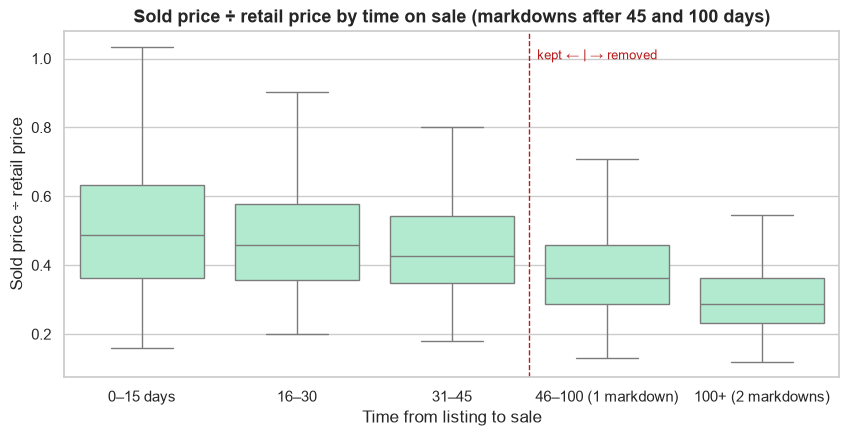

In [2]:
sales = load_sales()
data = before_markdown(sales)
removed = len(sales) - len(data)
print(f"Sold pairs (paid/shipped/delivered/completed): {len(sales):,} · sold within {MAX_DAYS_ON_SALE} days: {len(data):,} · removed: {removed:,} ({removed / len(sales):.0%})")

sales["price/retail"] = sales["sold_price"] / sales["retail_price"]
sales["time on sale"] = pd.cut(sales["days_to_sell"], [-1, 15, 30, 45, 100, 10_000], labels=["0–15 days", "16–30", "31–45", "46–100 (1 markdown)", "100+ (2 markdowns)"])
summary = sales.groupby("time on sale", observed=True).agg(pairs=("sold_price", "size"), median_ratio=("price/retail", "median"), median_price=("sold_price", "median"))
display(summary.style.format({"median_ratio": "{:.2f}", "median_price": "RM {:,.0f}"}))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=sales, x="time on sale", y="price/retail", color="#a7f3d0", ax=ax, showfliers=False)
ax.axvline(2.5, color="#b91c1c", ls="--", lw=1)
ax.text(2.55, ax.get_ylim()[1] * 0.95, "kept ← | → removed", color="#b91c1c", fontsize=9, va="top")
ax.set(title="Sold price ÷ retail price by time on sale (markdowns after 45 and 100 days)", xlabel="Time from listing to sale", ylabel="Sold price ÷ retail price")
save(fig, "06_markdown_bias.png")
plt.show()

**Finding:** Of 2,518 sold pairs, **824 (33%) are removed** because they sold more than 45 days after listing, leaving **1,694** for training. The bias is clear in the table: pairs sold within 15 days went for a median 0.49× retail, at 31–45 days 0.43×, after one markdown 0.36× and after two 0.29×. Training on all sales would have pulled every suggestion down toward marked-down prices.

## 2. Time-based split
Sorted by sale date: the **first 80%** of sales train the models, the **last 20%** test them. That's how the tool is used: learn from past sales,
price stock that is listed later. (A random split would let the model see sales from the same weeks it is tested on.)

In [3]:
data = data.sort_values("ordered_at").reset_index(drop=True)
cut = int(len(data) * 0.8)
train, test = data.iloc[:cut], data.iloc[cut:]
print(f"Train: {len(train):,} sales, {train['ordered_at'].min():%d %b %Y} – {train['ordered_at'].max():%d %b %Y}")
print(f"Test:  {len(test):,} sales, {test['ordered_at'].min():%d %b %Y} – {test['ordered_at'].max():%d %b %Y}")
print(f"Models in test but not in train: {sorted(set(test['name']) - set(train['name'])) or 'none'}")
print(f"Price range in test: RM {test['sold_price'].min():,.0f} – {test['sold_price'].max():,.0f}, median RM {test['sold_price'].median():,.0f}")
data[FEATURES].head(3)

Train: 1,355 sales, 01 Nov 2024 – 25 Jul 2026
Test:  339 sales, 25 Jul 2026 – 07 Nov 2026
Models in test but not in train: none
Price range in test: RM 40 – 685, median RM 235


,brand,name,category,condition,sole_condition,color,material,box_included,size,retail_price,months_since_start
0,Vans,Vans Old Skool,Casual,good,good,Navy,Suede,1,10.50,289.00,-0.08
1,Converse,Converse Chuck Taylor All Star,Casual,good,good,White,Canvas,0,11.00,249.00,-0.77
2,Adidas,Adidas Samba OG,Casual,like_new,excellent,Black/White,Leather,0,11.00,459.00,-0.57


## 3. The models, in simple words

| Model | How it prices a pair | Why it's here |
|---|---|---|
| **Baseline** | Look up what share of retail price the same model in the same condition usually sold for (median), and multiply by the retail price. If fewer than 3 sales: same brand + condition, then just condition. | What an experienced admin would do by hand. A model must beat it. |
| **Ridge regression** | A straight-line formula: price = a base + an amount for each feature (e.g. +RM40 for like new), with a small penalty that keeps amounts modest. | Simple and transparent. |
| **Random forest** | 400 decision trees, each trained on a random sample; the price is their average. | Captures combinations (e.g. a box matters more for hyped models). |
| **XGBoost** | Small trees built one after another, each correcting the previous ones' errors. | Usually the strongest on tables of data. |
| **LightGBM** | The same idea as XGBoost, with a different way of growing the trees. | A second gradient-boosting library to compare. |

**Two targets for the tree models:** predict the **price** in RM directly, or predict the **price ÷ retail ratio** and multiply back by the retail price.
The ratio puts a RM300 and a RM900 shoe on the same scale ("sold at 45% of retail"), which may help, especially for models with few sales.

**80% price range:** each model is checked with 5-fold cross-validation on the training data; the 10th and 90th percentile of actual ÷ predicted
are then applied to every new prediction. On the test set we check how often the real price falls inside.

## 4. Price or price ÷ retail? (tree models)

In [4]:
variants = {}
for cls in (RandomForestModel, XGBoostModel, LightGBMModel):
    for target in ("price", "ratio"):
        model = cls(target).fit(train[FEATURES], train["sold_price"])
        variants[model.name] = (model, metrics(test["sold_price"], model.predict(test[FEATURES])))
target_table = pd.DataFrame({name: m for name, (_, m) in variants.items()}).T[["MAE (RM)", "RMSE (RM)", "MAPE (%)", "within 15% (%)"]]
target_table["family"] = [n.split(" (")[0] for n in target_table.index]
kept = target_table.loc[target_table.groupby("family")["MAE (RM)"].idxmin()].index.tolist()
target_table["kept"] = target_table.index.isin(kept)
print("Kept (lower test MAE per model):", ", ".join(kept))
target_table.drop(columns="family").style.format({"MAE (RM)": "RM {:.2f}", "RMSE (RM)": "RM {:.2f}", "MAPE (%)": "{:.1f}%", "within 15% (%)": "{:.0f}%"})

Kept (lower test MAE per model): LightGBM (ratio), Random forest (ratio), XGBoost (ratio)


,MAE (RM),RMSE (RM),MAPE (%),within 15% (%),kept
Random forest (price),RM 29.57,RM 42.40,11.7%,71%,False
Random forest (ratio),RM 28.73,RM 41.39,11.3%,75%,True
XGBoost (price),RM 48.05,RM 58.38,29.0%,44%,False
XGBoost (ratio),RM 42.19,RM 53.26,21.8%,46%,True
LightGBM (price),RM 35.32,RM 45.96,18.1%,57%,False
LightGBM (ratio),RM 31.81,RM 43.21,14.7%,61%,True


**Finding:** For all three tree models, predicting **price ÷ retail** beats predicting the price directly: Random forest RM 28.73 vs 29.57, LightGBM RM 31.81 vs 35.32, XGBoost RM 42.19 vs 48.05 MAE. The ratio version is kept for each. The gain is largest for the boosted models. Expressing price as a share of retail puts cheap and expensive shoes on one scale, and unseen models benefit most (Random forest unseen-model MAE RM 60.5 with the ratio vs RM 70.9 with the price).

## 5. Comparison: time-based test and unseen models
- **Time-based test:** trained on the first 80% of sales, tested on the last 20%.
- **Unseen-model test:** 5-fold *group* cross-validation by model name. Each fold leaves out whole shoe models (all their sales), so the model must price
  a shoe it has **never seen**, from brand, category, condition, retail price and so on. This is what happens when the shop starts selling a new model.

Metrics: **MAE** and **RMSE** in RM, **R²** (share of price differences explained), **MAPE** (average % error), the share of predictions within
**±RM20** and within **±15%**, and how often the real price fell inside the **80% range** (should be about 80%).

In [5]:
candidates = {"Baseline (median ratio)": RatioBaseline(), "Ridge (price)": RidgeModel("price")}
candidates.update({name: model for name, (model, _) in variants.items()})
rows = {}
for name, model in candidates.items():
    if name not in variants:
        model.fit(train[FEATURES], train["sold_price"])
    rows[name] = metrics(test["sold_price"], model.predict(test[FEATURES]))

groups = data["name"]
unseen = {}
for name, model in candidates.items():
    errors = []
    for tr, te in GroupKFold(n_splits=5).split(data, groups=groups):
        fold = type(model)() if isinstance(model, (RatioBaseline,)) else type(model)(model.target)
        fold.fit(data.iloc[tr][FEATURES], data.iloc[tr]["sold_price"], calibrate=False)
        errors.append(np.abs(fold.predict(data.iloc[te][FEATURES])["yhat"].to_numpy() - data.iloc[te]["sold_price"].to_numpy()))
    unseen[name] = np.concatenate(errors).mean()

results = pd.DataFrame(rows).T
results["unseen-model MAE (RM)"] = pd.Series(unseen)
results["target"] = ["ratio" if "ratio" in n else "price" for n in results.index]
results["kept for selection"] = [n in kept or n.startswith(("Baseline", "Ridge")) for n in results.index]
results = results.sort_values("MAE (RM)")
results.rename_axis("model").reset_index().round(3).to_csv(REPORT_DIR / "price_model_comparison.csv", index=False)
print("saved reports/price_model_comparison.csv")
results.style.format({"MAE (RM)": "RM {:.2f}", "RMSE (RM)": "RM {:.2f}", "R2": "{:.3f}", "MAPE (%)": "{:.1f}%", "within RM20 (%)": "{:.0f}%",
                      "within 15% (%)": "{:.0f}%", "80% range coverage (%)": "{:.0f}%", "unseen-model MAE (RM)": "RM {:.2f}"})

saved reports/price_model_comparison.csv


,MAE (RM),RMSE (RM),R2,MAPE (%),within RM20 (%),within 15% (%),80% range coverage (%),unseen-model MAE (RM),target,kept for selection
Random forest (ratio),RM 28.73,RM 41.39,0.912,11.3%,53%,75%,81%,RM 60.54,ratio,True
Random forest (price),RM 29.57,RM 42.40,0.908,11.7%,50%,71%,80%,RM 70.91,price,False
LightGBM (ratio),RM 31.81,RM 43.21,0.904,14.7%,41%,61%,69%,RM 63.29,ratio,True
Baseline (median ratio),RM 34.92,RM 52.29,0.860,12.4%,51%,66%,78%,RM 81.79,ratio,True
LightGBM (price),RM 35.32,RM 45.96,0.891,18.1%,32%,57%,62%,RM 74.17,price,False
Ridge (price),RM 37.14,RM 54.45,0.848,16.3%,42%,63%,77%,RM 81.42,price,True
XGBoost (ratio),RM 42.19,RM 53.26,0.854,21.8%,28%,46%,55%,RM 65.30,ratio,True
XGBoost (price),RM 48.05,RM 58.38,0.825,29.0%,22%,44%,52%,RM 79.41,price,False


**Finding:** **Random forest (ratio) is best on every test metric**: MAE **RM 28.73**, RMSE RM 41.39, R² 0.91, MAPE 11.3%, 53% of prices within ±RM20 and **75% within ±15%**. Its 80% range covers **81%** of real prices. The baseline (median ratio of the same model and condition) is a strong reference at RM 34.92 and covers 78%. Ridge (RM 37.14) is worse than the baseline. LightGBM (RM 31.81) is second, and XGBoost does poorly on this later test period (RM 42.19, R² 0.85). Both boosted models' ranges also cover far less than 80% (69% and 55%): their cross-validated errors on the training period understate their errors on later sales. On **models never seen in training**, every model's error roughly doubles: Random forest RM 60.5, LightGBM RM 63.3, XGBoost RM 65.3, against RM 81.8 for the baseline (which can only fall back to brand + condition).

saved 06_mae_by_model.png


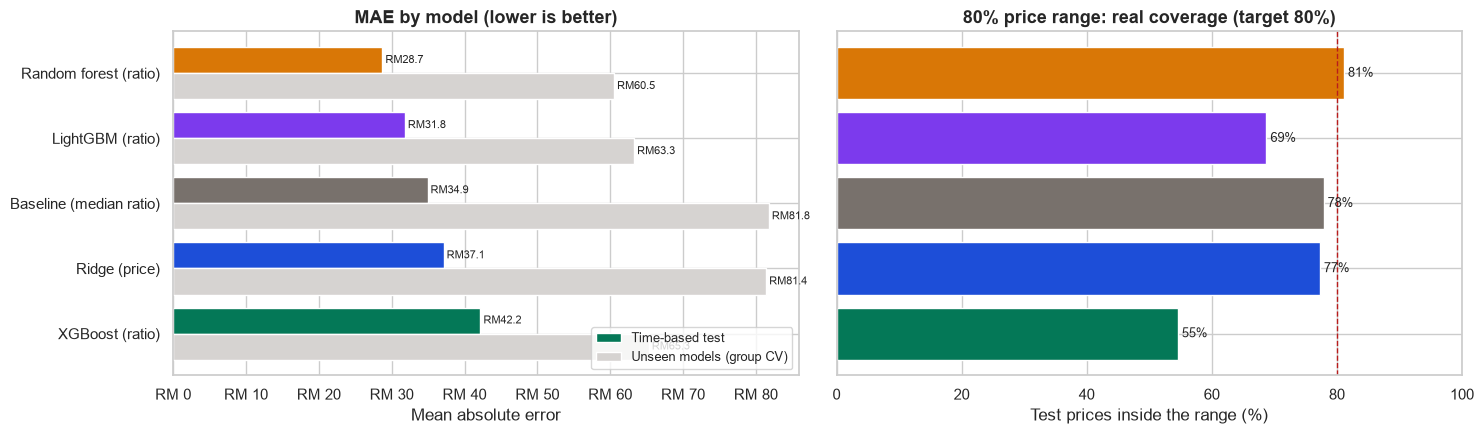

In [6]:
shown = results[results["kept for selection"]].sort_values("MAE (RM)", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
y = np.arange(len(shown))
axes[0].barh(y + 0.2, shown["MAE (RM)"], 0.4, color=[color_of(n) for n in shown.index], label="Time-based test")
axes[0].barh(y - 0.2, shown["unseen-model MAE (RM)"], 0.4, color="#d6d3d1", label="Unseen models (group CV)")
for i, (a, b) in enumerate(zip(shown["MAE (RM)"], shown["unseen-model MAE (RM)"])):
    axes[0].text(a, i + 0.2, f" RM{a:.1f}", va="center", fontsize=8)
    axes[0].text(b, i - 0.2, f" RM{b:.1f}", va="center", fontsize=8)
axes[0].set_yticks(y, shown.index)
axes[0].set(title="MAE by model (lower is better)", xlabel="Mean absolute error")
rm_axis(axes[0], "x")
axes[0].legend(loc="lower right", fontsize=9)
axes[1].barh(y, shown["80% range coverage (%)"], color=[color_of(n) for n in shown.index])
axes[1].axvline(80, color="#b91c1c", ls="--", lw=1)
for i, v in enumerate(shown["80% range coverage (%)"]):
    axes[1].text(v, i, f" {v:.0f}%", va="center", fontsize=9)
axes[1].set_yticks(y, [""] * len(y))
axes[1].set(title="80% price range: real coverage (target 80%)", xlabel="Test prices inside the range (%)", xlim=(0, 100))
fig.tight_layout()
save(fig, "06_mae_by_model.png")
plt.show()

## 6. Choosing the model
**Rule (set before looking at the results):** lowest MAE on the time-based test wins. If the gap between the top two is not significant
(a paired bootstrap 90% interval of their MAE difference includes 0), it's a tie, and the **unseen-model MAE** decides.

In [7]:
finalists = results[results["kept for selection"]].sort_values("MAE (RM)")
first, second = finalists.index[:2]
pred = {n: candidates[n].predict(test[FEATURES])["yhat"].to_numpy() for n in (first, second)}
abs_err = {n: np.abs(p - test["sold_price"].to_numpy()) for n, p in pred.items()}
rng = np.random.default_rng(0)
gaps = [(abs_err[second][idx] - abs_err[first][idx]).mean() for idx in (rng.integers(0, len(test), len(test)) for _ in range(2000))]
low, high = np.percentile(gaps, [5, 95])
tied = low <= 0
print(f"Top two: {first} (MAE RM{finalists.loc[first, 'MAE (RM)']:.2f}) and {second} (RM{finalists.loc[second, 'MAE (RM)']:.2f})")
print(f"MAE gap {finalists.loc[second, 'MAE (RM)'] - finalists.loc[first, 'MAE (RM)']:.2f}, paired 90% interval {low:+.2f} … {high:+.2f} -> {'tie' if tied else 'significant'}")
best_name = min((first, second), key=lambda n: finalists.loc[n, "unseen-model MAE (RM)"]) if tied else first
print(f"Chosen: {best_name}" + (" (tie, unseen-model MAE decides)" if tied else ""))

Top two: Random forest (ratio) (MAE RM28.73) and LightGBM (ratio) (RM31.81)
MAE gap 3.08, paired 90% interval +1.56 … +4.67 -> significant
Chosen: Random forest (ratio)


**Finding:** The top two are Random forest (ratio), RM 28.73, and LightGBM (ratio), RM 31.81. The paired bootstrap interval of the MAE gap is +RM1.56 … +RM4.67, which excludes 0, so the difference is **significant**: no tie, and the **Random forest (ratio)** is chosen on MAE alone. It also has the best unseen-model MAE (RM 60.5), so the tiebreak would have picked it too.

saved 06_predicted_vs_actual.png


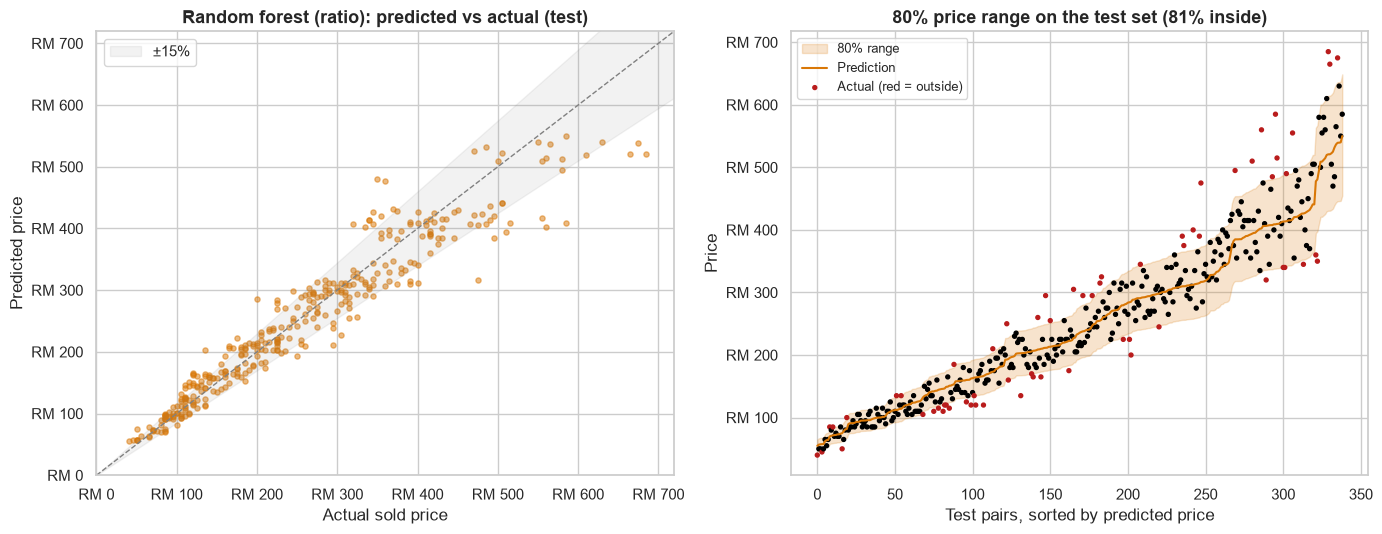

In [8]:
best = candidates[best_name]
best_pred = best.predict(test[FEATURES])
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(test["sold_price"], best_pred["yhat"], s=14, alpha=0.5, color=color_of(best_name))
lim = max(test["sold_price"].max(), best_pred["yhat"].max()) * 1.05
axes[0].plot([0, lim], [0, lim], color="grey", ls="--", lw=1)
axes[0].fill_between([0, lim], [0, lim * 0.85], [0, lim * 1.15], color="grey", alpha=0.1, label="±15%")
axes[0].set(title=f"{best_name}: predicted vs actual (test)", xlabel="Actual sold price", ylabel="Predicted price", xlim=(0, lim), ylim=(0, lim))
rm_axis(axes[0]); rm_axis(axes[0], "x")
axes[0].legend()
order = np.argsort(best_pred["yhat"].to_numpy())
inside = (test["sold_price"].to_numpy() >= best_pred["lower"].to_numpy()) & (test["sold_price"].to_numpy() <= best_pred["upper"].to_numpy())
axes[1].fill_between(np.arange(len(order)), best_pred["lower"].to_numpy()[order], best_pred["upper"].to_numpy()[order], color=color_of(best_name), alpha=0.2, label="80% range")
axes[1].plot(np.arange(len(order)), best_pred["yhat"].to_numpy()[order], color=color_of(best_name), lw=1.5, label="Prediction")
axes[1].scatter(np.arange(len(order)), test["sold_price"].to_numpy()[order], s=8, c=np.where(inside[order], "black", "#b91c1c"), label="Actual (red = outside)")
axes[1].set(title=f"80% price range on the test set ({inside.mean():.0%} inside)", xlabel="Test pairs, sorted by predicted price", ylabel="Price")
rm_axis(axes[1])
axes[1].legend(fontsize=9)
fig.tight_layout()
save(fig, "06_predicted_vs_actual.png")
plt.show()

**Finding:** Predictions follow the actual prices closely across the whole range (RM 40 – 685), and most points sit inside the ±15% band. The biggest misses are on the most expensive pairs (hyped models in like-new condition), where single sales vary most. The 80% range contains 81% of test prices, so for the chosen model the calibrated range is honest.

## 7. Why the model suggests a price: SHAP
**SHAP** splits each prediction into a starting value (the average pair) plus one amount per feature, so they add up exactly to the suggested price.
For a ratio model the amounts are in "share of retail" and are converted to RM by multiplying by the pair's retail price. Categories that were
one-hot encoded (e.g. one column per brand) are added back together into one amount per feature.

saved 06_shap_importance.png


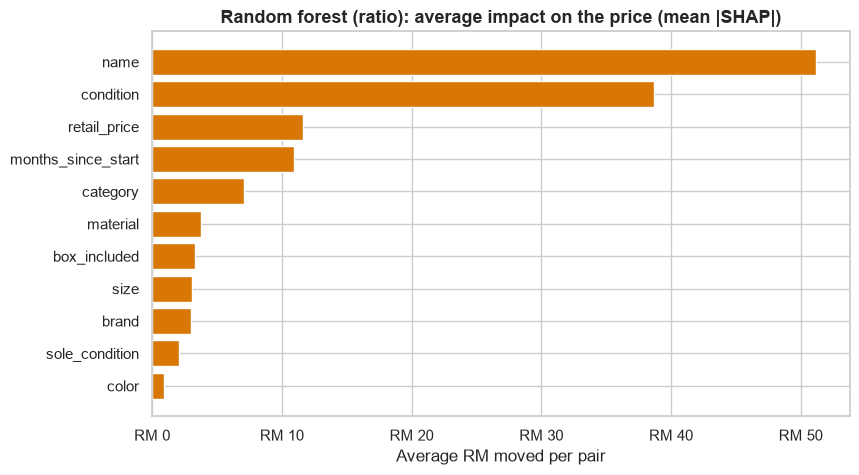

saved 06_shap_summary.png


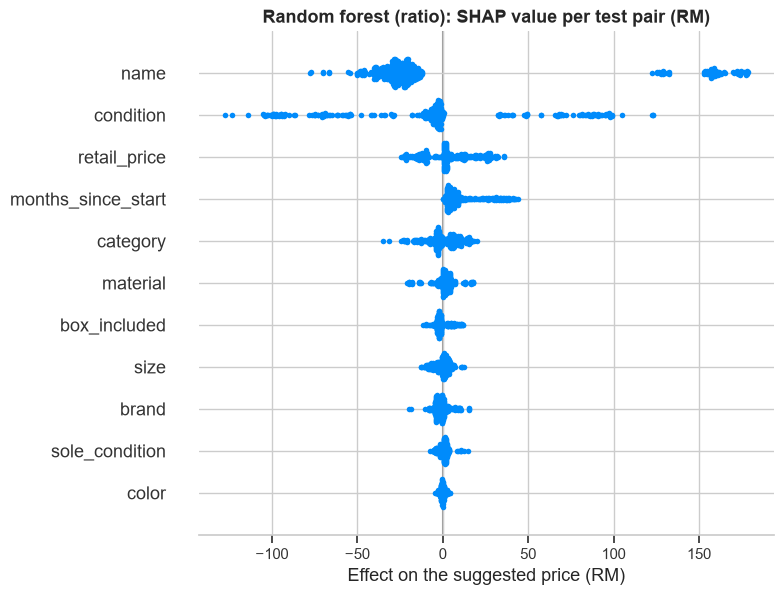

Average RM effect: name 51, condition 39, retail_price 12, months_since_start 11, category 7, material 4, box_included 3, size 3, brand 3, sole_condition 2, color 1


In [9]:
import shap

contrib = best.explain(test[FEATURES])
features_only = contrib.drop(columns="base")
assert np.allclose(contrib.sum(axis=1), best_pred["yhat"], atol=1.0), "SHAP parts don't add up to the prediction"
mean_abs = features_only.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(mean_abs.index, mean_abs.values, color=color_of(best_name))
ax.set(title=f"{best_name}: average impact on the price (mean |SHAP|)", xlabel="Average RM moved per pair")
rm_axis(ax, "x")
save(fig, "06_shap_importance.png")
plt.show()

plt.figure()
shap.summary_plot(features_only[mean_abs.index[::-1]].to_numpy(), feature_names=list(mean_abs.index[::-1]), show=False, color_bar=False)
plt.title(f"{best_name}: SHAP value per test pair (RM)", fontweight="bold")
plt.xlabel("Effect on the suggested price (RM)")
save(plt.gcf(), "06_shap_summary.png")
plt.show()
print("Average RM effect:", ", ".join(f"{f} {v:,.0f}" for f, v in mean_abs.sort_values(ascending=False).items()))

**Finding:** On average the **model** moves the price most (about RM 51 per pair), then **condition** (RM 39), then retail price (RM 12) and listing date (RM 11, demand for some models changing over time). Category, material, box, size, brand, sole condition and colour each move it by RM 1–7 on average. The SHAP plot shows why the model matters so much: most models sit slightly below average (−RM 20 to −40), while the **Adidas Samba OG** adds about RM 120–180, the hype premium seen in notebook 01. Condition spreads from about −RM 130 (fair) to +RM 120 (like new).

### Three example pairs from the test set, with their top reasons

Adidas Samba OG, UK 8.5, like_new, sole excellent, box no, retail RM459: predicted RM550 (sold RM585) · start RM230 · name +178, condition +99, months_since_start +44, material +5, brand -5
Nike Dunk Low, UK 8, good, sole good, box yes, retail RM459: predicted RM236 (sold RM220) · start RM230 · name -27, box_included +10, category +10, brand +4, sole_condition +3
Crocs Classic Clog, UK 4, fair, sole worn, box no, retail RM249: predicted RM55 (sold RM40) · start RM125 · condition -30, name -17, retail_price -13, category -5, months_since_start +3


saved 06_shap_examples.png


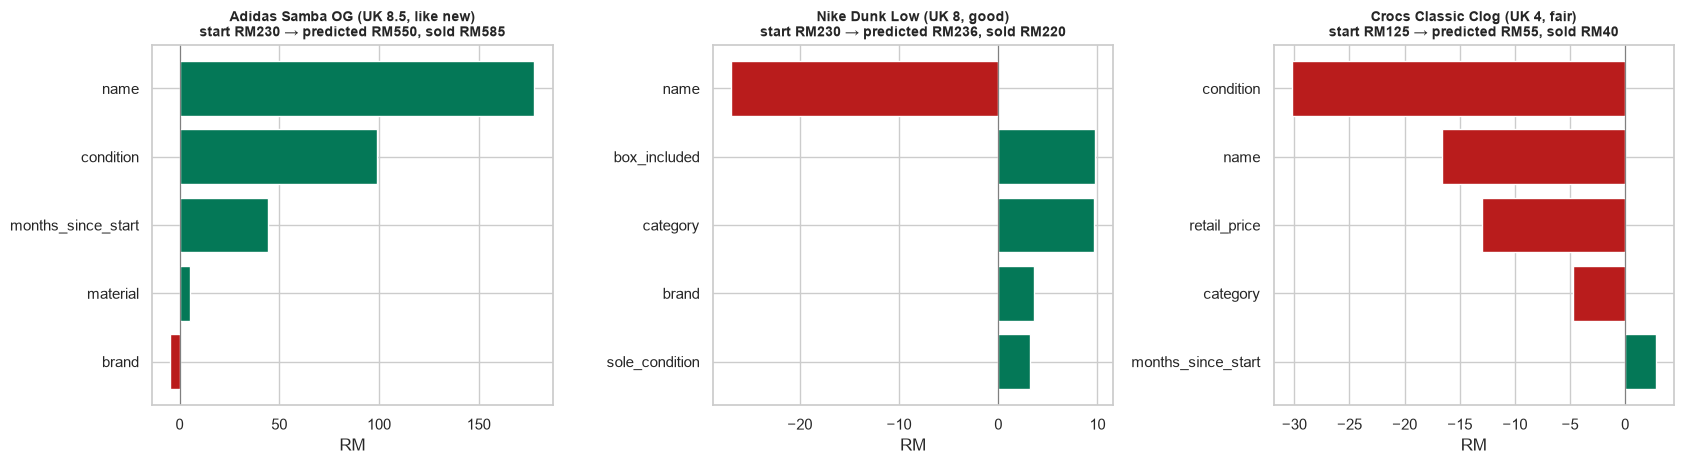

In [10]:
examples = test.assign(pred=best_pred["yhat"]).iloc[[int(np.argmax(best_pred["yhat"].to_numpy())), int(np.argsort(best_pred["yhat"].to_numpy())[len(test) // 2]), int(np.argmin(best_pred["yhat"].to_numpy()))]]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (idx, pair) in zip(axes, examples.iterrows()):
    parts = contrib.loc[idx].drop("base")
    top = parts.reindex(parts.abs().sort_values(ascending=False).index).head(5)
    ax.barh(top.index[::-1], top.values[::-1], color=np.where(top.values[::-1] >= 0, "#047857", "#b91c1c"))
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"{pair['name']} (UK {pair['size']:g}, {pair['condition'].replace('_', ' ')})\nstart RM{contrib.loc[idx, 'base']:,.0f} → predicted RM{pair['pred']:,.0f}, sold RM{pair['sold_price']:,.0f}", fontsize=10)
    ax.set_xlabel("RM")
    print(f"{pair['name']}, UK {pair['size']:g}, {pair['condition']}, sole {pair['sole_condition']}, box {'yes' if pair['box_included'] else 'no'}, retail RM{pair['retail_price']:,.0f}: "
          f"predicted RM{pair['pred']:,.0f} (sold RM{pair['sold_price']:,.0f}) · start RM{contrib.loc[idx, 'base']:,.0f} · " + ", ".join(f"{f} {v:+,.0f}" for f, v in top.items()))
fig.tight_layout()
save(fig, "06_shap_examples.png")
plt.show()

**Finding:** The three examples read naturally. A like-new **Samba OG** starts from the average pair (RM 230), gets +RM 178 for the model, +RM 99 for condition and +RM 44 for current demand, giving RM 550 (it sold for RM 585). A good **Dunk Low** is close to average (RM 236 predicted, sold RM 220): −RM 27 for the model, +RM 10 for the box. A fair **Crocs Classic Clog** with a worn sole is pushed down by condition (−RM 30), model (−RM 17) and its low retail price, giving RM 55 (sold RM 40).

## 8. Final model
The chosen model is retrained on **all** pairs sold within 45 days of listing and saved to `models/price_model.joblib` (+ JSON metadata).
It also stores the median retail price per model and brand, which `recommend_price` uses when a new pair has no retail price.

In [11]:
final = type(best)() if isinstance(best, RatioBaseline) else type(best)(best.target)
final.fit(data[FEATURES], data["sold_price"])
final.retail_reference_ = retail_reference()
final.known_models_ = set(data["name"])
model_path = MODEL_DIR / "price_model.joblib"
joblib.dump(final, model_path)
row = results.loc[best_name]
metadata = {
    "model_name": best_name,
    "model_class": f"pricing.models.{type(final).__name__}",
    "target": f"{'sold price / retail price, multiplied back' if final.target == 'ratio' else 'sold price (RM)'}; trained on order_items.price",
    "training_data": f"pairs sold (paid/shipped/delivered/completed) within {MAX_DAYS_ON_SALE} days of listing: {len(data):,} of {len(sales):,} sold pairs",
    "markdown_bias_fix": f"pairs sold after {MAX_DAYS_ON_SALE} days are excluded (they sold at marked-down prices)",
    "features": FEATURES,
    "price_range": {"method": "10th/90th percentile of actual/predicted from 5-fold out-of-fold predictions", "multipliers": list(final.range_)},
    "selection": "lowest MAE on a time-based test (last 20% of sales); unseen-model MAE (group CV by model) breaks statistical ties",
    "evaluation": {"time_test": {"train_until": f"{train['ordered_at'].max():%Y-%m-%d}", "test_from": f"{test['ordered_at'].min():%Y-%m-%d}",
                                 "metrics": {k: round(float(v), 3) for k, v in row.items() if isinstance(v, (int, float, np.floating))}},
                   "all_models": results.rename_axis("model").reset_index().round(3).to_dict(orient="records")},
    "trained_until": f"{data['ordered_at'].max():%Y-%m-%d}",
    "rounding": "suggested price rounded to the nearest RM5",
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "versions": {p: version(p) for p in ["pandas", "numpy", "scikit-learn", "xgboost", "lightgbm", "shap", "joblib"]},
    "load": "sys.path.insert(0, 'ml-service'); from pricing.recommend import recommend_price; recommend_price({...})",
}
(MODEL_DIR / "price_model.json").write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")
assert np.allclose(joblib.load(model_path).predict(test[FEATURES].head(20))["yhat"], final.predict(test[FEATURES].head(20))["yhat"])
print(f"saved {model_path.name} + price_model.json ({best_name}, {len(data):,} rows) · reload check passed")

saved price_model.joblib + price_model.json (Random forest (ratio), 1,694 rows) · reload check passed


## 9. Demo: `recommend_price` for 5 pairs
Four known models (one without a retail price, to show the fallback) and one model the shop has **never sold**: Nike Air Max 90, retail RM599.

**How the reasons are built, so they add up:**
1. **Starting point:** retail price × the model's typical resale ratio (its average ratio, about 51%).
2. The **4 biggest contributions** in RM: SHAP values on the ratio, converted with this pair's retail price.
   The retail price itself isn't listed as a reason, because it is already in the starting point; its small effect on the ratio is part of "Other details".
   "Months since start" is shown as **"Current popularity of this model"**.
3. **Other details:** all remaining features together.

Starting point + contributions + other details = the model's estimate; the suggested price is that rounded to the nearest RM5.

**Flags:** `above_retail` (with the warning "Above original retail price - hyped model, check before listing."; the price is not capped) and
`unseen_model` (with "New model with no sales history - price is less certain (typical error about RM60).", from the unseen-model test).

In [12]:
ref = final.retail_reference_
mode = lambda name, col: data.loc[data["name"] == name, col].mode()[0]  # noqa: E731
demo = [
    {"name": "Adidas Samba OG", "brand": "Adidas", "category": mode("Adidas Samba OG", "category"), "condition": "like_new", "sole_condition": "excellent",
     "box_included": True, "size": 7.5, "color": mode("Adidas Samba OG", "color"), "material": mode("Adidas Samba OG", "material"), "retail_price": None},
    {"name": "Nike Dunk Low", "brand": "Nike", "category": mode("Nike Dunk Low", "category"), "condition": "good", "sole_condition": "good",
     "box_included": False, "size": 9, "color": mode("Nike Dunk Low", "color"), "material": mode("Nike Dunk Low", "material"), "retail_price": ref["name"]["Nike Dunk Low"]},
    {"name": "Dr. Martens 1460 Boot", "brand": "Dr. Martens", "category": mode("Dr. Martens 1460 Boot", "category"), "condition": "fair", "sole_condition": "worn",
     "box_included": False, "size": 6, "color": mode("Dr. Martens 1460 Boot", "color"), "material": mode("Dr. Martens 1460 Boot", "material"), "retail_price": ref["name"]["Dr. Martens 1460 Boot"]},
    {"name": "Converse Chuck 70", "brand": "Converse", "category": mode("Converse Chuck 70", "category"), "condition": "like_new", "sole_condition": "excellent",
     "box_included": True, "size": 5, "color": mode("Converse Chuck 70", "color"), "material": mode("Converse Chuck 70", "material"), "retail_price": ref["name"]["Converse Chuck 70"]},
    {"name": "Nike Air Max 90", "brand": "Nike", "category": "Sneakers", "condition": "good", "sole_condition": "good",
     "box_included": False, "size": 8.5, "color": "White", "material": "Leather", "retail_price": 599},
]
rows = []
for product in demo:
    rec = recommend_price(product, model=final, listed_at="2026-11-08")
    total = sum(b["rm"] for b in rec["breakdown"])
    assert abs(total - rec["model_estimate"]) < 0.01, "reasons don't add up"
    label = f"{product['name']}, UK {product['size']:g}, {product['condition'].replace('_', ' ')}, sole {product['sole_condition']}, {'box' if product['box_included'] else 'no box'}"
    rows.append({"pair": label, "retail used": f"RM{rec['retail_price_used']:,.0f}", "suggested": f"RM{rec['suggested_price']}",
                 "80% range": f"RM{rec['range_80'][0]} – RM{rec['range_80'][1]}", "above retail": rec["above_retail"], "unseen model": rec["unseen_model"]})
    print(f"\n{label} -> RM{rec['suggested_price']} (80% range RM{rec['range_80'][0]} – RM{rec['range_80'][1]})")
    for line in rec["reasons"]:
        print("   ", line)
    print(f"    = RM{total:,.2f} (model estimate) -> rounded to RM{rec['suggested_price']}")
    for text in rec["warnings"]:
        print("    WARNING:", text)
    for text in rec["notes"]:
        print("    Note:", text)
pd.DataFrame(rows)


Adidas Samba OG, UK 7.5, like new, sole excellent, box -> RM615 (80% range RM515 – RM720)
    Retail RM459 x typical resale ratio 51% = RM233
    Model Adidas Samba OG: +RM207
    Like new condition: +RM110
    Current popularity of this model: +RM58
    Original box included: +RM5
    Other details: +RM2
    = RM615.86 (model estimate) -> rounded to RM615
    Note: Retail price not given: used RM459 (the median for Adidas Samba OG).



Nike Dunk Low, UK 9, good, sole good, no box -> RM225 (80% range RM190 – RM265)
    Retail RM459 x typical resale ratio 51% = RM233
    Model Nike Dunk Low: -RM35
    Current popularity of this model: +RM8
    Leather material: +RM6
    Category Sneakers: +RM6
    Other details: +RM8
    = RM226.03 (model estimate) -> rounded to RM225



Dr. Martens 1460 Boot, UK 6, fair, sole worn, no box -> RM255 (80% range RM210 – RM300)
    Retail RM899 x typical resale ratio 51% = RM457
    Fair condition: -RM128
    Model Dr. Martens 1460 Boot: -RM56
    Current popularity of this model: +RM13
    Category Boots: -RM11
    Other details: -RM20
    = RM254.36 (model estimate) -> rounded to RM255



Converse Chuck 70, UK 5, like new, sole excellent, box -> RM220 (80% range RM185 – RM255)
    Retail RM349 x typical resale ratio 51% = RM177
    Like new condition: +RM57
    Model Converse Chuck 70: -RM23
    Current popularity of this model: +RM11
    Original box included: +RM7
    Other details: -RM10
    = RM219.61 (model estimate) -> rounded to RM220



Nike Air Max 90, UK 8.5, good, sole good, no box -> RM355 (80% range RM295 – RM415)
    Retail RM599 x typical resale ratio 51% = RM304
    Nike Air Max 90 is a new model (no sales history yet): -RM38
    Current popularity of this model: +RM20
    Category Sneakers: +RM11
    Size UK 8.5: +RM11
    Other details: +RM45
    = RM352.91 (model estimate) -> rounded to RM355


,pair,retail used,suggested,80% range,above retail,unseen model
0,"Adidas Samba OG, UK 7.5, like new, sole excell...",RM459,RM615,RM515 – RM720,True,False
1,"Nike Dunk Low, UK 9, good, sole good, no box",RM459,RM225,RM190 – RM265,False,False
2,"Dr. Martens 1460 Boot, UK 6, fair, sole worn, ...",RM899,RM255,RM210 – RM300,False,False
3,"Converse Chuck 70, UK 5, like new, sole excell...",RM349,RM220,RM185 – RM255,False,False
4,"Nike Air Max 90, UK 8.5, good, sole good, no box",RM599,RM355,RM295 – RM415,False,True


**Finding:** `recommend_price` now gives reasons that **add up**: starting point (retail × the model's typical resale ratio of 51%) + the 4 biggest contributions + "Other details" = the model's estimate, before rounding to RM5 (checked by an assert for every pair). The like-new **Samba OG** without a retail price uses the model's median retail (RM 459, given as a note): RM 233 start, +RM 207 for the model, +RM 110 for condition, +RM 58 for current popularity, giving **RM 615**. That's above retail, so it gets `above_retail` and a warning to check before listing (the price is not capped). A good **Dunk Low** comes to **RM 225**, a fair **Dr. Martens 1460** with a worn sole **RM 255** (−RM 128 for condition) and a like-new **Chuck 70** with box **RM 220**. The unseen **Nike Air Max 90** (retail RM 599) gets **RM 355** with `unseen_model` and the warning that its price is less certain (typical error about RM 60). Its "Other details" are larger (+RM 45), mostly the retail price's own effect on the ratio, which isn't shown as a separate reason.

## 10. Summary

- **Markdown bias fixed:** 824 of 2,518 sales (33%) sold after 45 days at marked-down prices and are excluded; 1,694 pairs train the model.
- **Price ÷ retail beats price** for every tree model, so all are trained on the ratio.
- **Chosen: Random forest (ratio)**, best on the time-based test (MAE RM 28.73, R² 0.91, 75% within ±15%), significantly better than LightGBM (paired bootstrap), and best on unseen models too (RM 60.5).
- **Honest 80% range:** it contains 81% of real test prices. The boosted models' ranges under-cover (55–69%) on later sales.
- **Explainable, and the reasons add up:** each suggestion is the retail price × a typical resale ratio, plus the 4 biggest RM effects (SHAP) and "Other details". Model and condition matter most, then retail price and current popularity. Flags warn when a price is above retail or the model is new.
- **Limits:** unseen models are priced about twice as roughly (MAE about RM 60). Hyped models can be suggested above retail (Samba OG): flagged with a warning, not capped. Saved as `models/price_model.joblib`, used by `pricing.recommend.recommend_price()`.